In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    classification_report, 
    confusion_matrix,
    roc_auc_score
)
import matplotlib.pyplot as plt

загрузка и проверка данных

In [7]:
test_df = pd.read_csv('customer_churn_dataset-testing-master.csv')
test_df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [8]:
test_df.shape

(64374, 12)

In [9]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         64374 non-null  int64
 1   Age                64374 non-null  int64
 2   Gender             64374 non-null  str  
 3   Tenure             64374 non-null  int64
 4   Usage Frequency    64374 non-null  int64
 5   Support Calls      64374 non-null  int64
 6   Payment Delay      64374 non-null  int64
 7   Subscription Type  64374 non-null  str  
 8   Contract Length    64374 non-null  str  
 9   Total Spend        64374 non-null  int64
 10  Last Interaction   64374 non-null  int64
 11  Churn              64374 non-null  int64
dtypes: int64(9), str(3)
memory usage: 7.1 MB


In [10]:
test_df.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [11]:
test_df[test_df.isna().any(axis=1)]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn


In [12]:
test_df["Churn"].value_counts(normalize=True)

Churn
0    0.526315
1    0.473685
Name: proportion, dtype: float64

In [13]:
train_df = pd.read_csv('customer_churn_dataset-training-master.csv')
train_df = train_df.dropna(how="all")
train_df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [14]:
train_df.shape

(440832, 12)

In [15]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 440832 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  str    
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  str    
 8   Contract Length    440832 non-null  str    
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), str(3)
memory usage: 51.8 MB


In [16]:
train_df.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [17]:
train_df[train_df.isna().any(axis=1)]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn


In [18]:
train_df["Churn"].value_counts(normalize=True)

Churn
1.0    0.567107
0.0    0.432893
Name: proportion, dtype: float64

In [19]:
print(test_df["Age"].describe())
print(train_df["Age"].describe())
print()
print(test_df["Age"].describe() - train_df["Age"].describe())

count    64374.000000
mean        41.970982
std         13.924911
min         18.000000
25%         30.000000
50%         42.000000
75%         54.000000
max         65.000000
Name: Age, dtype: float64
count    440832.000000
mean         39.373153
std          12.442369
min          18.000000
25%          29.000000
50%          39.000000
75%          48.000000
max          65.000000
Name: Age, dtype: float64

count   -376458.000000
mean          2.597829
std           1.482542
min           0.000000
25%           1.000000
50%           3.000000
75%           6.000000
max           0.000000
Name: Age, dtype: float64


In [20]:
print(test_df["Tenure"].describe())
print(train_df["Tenure"].describe())
print()
print(test_df["Tenure"].describe() - train_df["Tenure"].describe())

count    64374.000000
mean        31.994827
std         17.098234
min          1.000000
25%         18.000000
50%         33.000000
75%         47.000000
max         60.000000
Name: Tenure, dtype: float64
count    440832.000000
mean         31.256336
std          17.255727
min           1.000000
25%          16.000000
50%          32.000000
75%          46.000000
max          60.000000
Name: Tenure, dtype: float64

count   -376458.000000
mean          0.738491
std          -0.157493
min           0.000000
25%           2.000000
50%           1.000000
75%           1.000000
max           0.000000
Name: Tenure, dtype: float64


In [21]:
print(test_df["Subscription Type"].value_counts(normalize=True))
print(train_df["Subscription Type"].value_counts(normalize=True))

Subscription Type
Standard    0.334017
Basic       0.333225
Premium     0.332759
Name: proportion, dtype: float64
Subscription Type
Standard    0.338288
Premium     0.337267
Basic       0.324446
Name: proportion, dtype: float64


In [22]:
print(test_df.groupby("Churn")["Tenure"].median())
print(train_df.groupby("Churn")["Tenure"].median())

Churn
0    27.0
1    37.0
Name: Tenure, dtype: float64
Churn
0.0    33.0
1.0    30.0
Name: Tenure, dtype: float64


In [23]:
train_df.groupby("Churn")[["Age","Tenure","Usage Frequency", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction"]].median()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,
0.0,37.0,33.0,17.0,1.0,10.0,749.98,12.0
1.0,42.0,30.0,15.0,5.0,15.0,534.00,16.0


In [24]:
train_df.groupby("Contract Length")["Churn"].mean()

Contract Length
Annual       0.460761
Monthly      1.000000
Quarterly    0.460256
Name: Churn, dtype: float64

In [25]:
test_df.groupby("Churn")[["Age","Tenure","Usage Frequency", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction"]].median()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,
0,41.0,27.0,16.0,4.0,12.0,568.0,16.0
1,44.0,37.0,14.0,7.0,23.0,491.0,15.0


In [26]:
test_df.groupby("Contract Length")["Churn"].mean()

Contract Length
Annual       0.462167
Monthly      0.516087
Quarterly    0.440482
Name: Churn, dtype: float64

In [27]:
pd.crosstab(train_df["Contract Length"], train_df["Churn"])

Churn,0.0,1.0
Contract Length,,
Annual,95552,81646
Monthly,0,87104
Quarterly,95281,81249


In [28]:
pd.crosstab(test_df["Contract Length"], test_df["Churn"])

Churn,0,1
Contract Length,,
Annual,11515,9895
Monthly,10709,11421
Quarterly,11657,9177


In [29]:
print(train_df.drop(columns="CustomerID").duplicated().sum())
print(test_df.drop(columns="CustomerID").duplicated().sum())

0
0


Train-validation split

In [30]:
X = train_df.drop(columns=["Churn","CustomerID"])
y = train_df["Churn"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y, 
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [31]:
categorical_features = [
    "Gender", 
    "Subscription Type",
    "Contract Length",
]

numeric_features = [
    column
    for column in X_train.columns
    if column not in categorical_features
]

print(categorical_features)
print(numeric_features)

['Gender', 'Subscription Type', 'Contract Length']
['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']


In [32]:
categorialEncoder = OneHotEncoder(handle_unknown="ignore")

In [33]:
#преобразование числовых и категориальных признаков

prepocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", categorialEncoder, categorical_features),
    ]
)

In [34]:
model = Pipeline(
    steps=[
        ("prepocessor", prepocessor),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

In [35]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Age','Gender','Tenure',...,'Contract Length','Total Spend', 'Last Interaction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [36]:
model.predict(X_val)

array([1., 0., 1., ..., 0., 1., 0.], shape=(88167,))

In [37]:
y_pred = model.predict(X_val)
y_proba = model.predict_proba(X_val)[:,1]

print(classification_report(y_val, y_pred))
print("confusion matrix")
print(confusion_matrix(y_val, y_pred))
print(f'roc-auc: {roc_auc_score(y_val, y_proba)}')

              precision    recall  f1-score   support

         0.0       0.86      0.90      0.88     38167
         1.0       0.92      0.89      0.90     50000

    accuracy                           0.89     88167
   macro avg       0.89      0.89      0.89     88167
weighted avg       0.89      0.89      0.89     88167

confusion matrix
[[34492  3675]
 [ 5726 44274]]
roc-auc: 0.9590262336573478


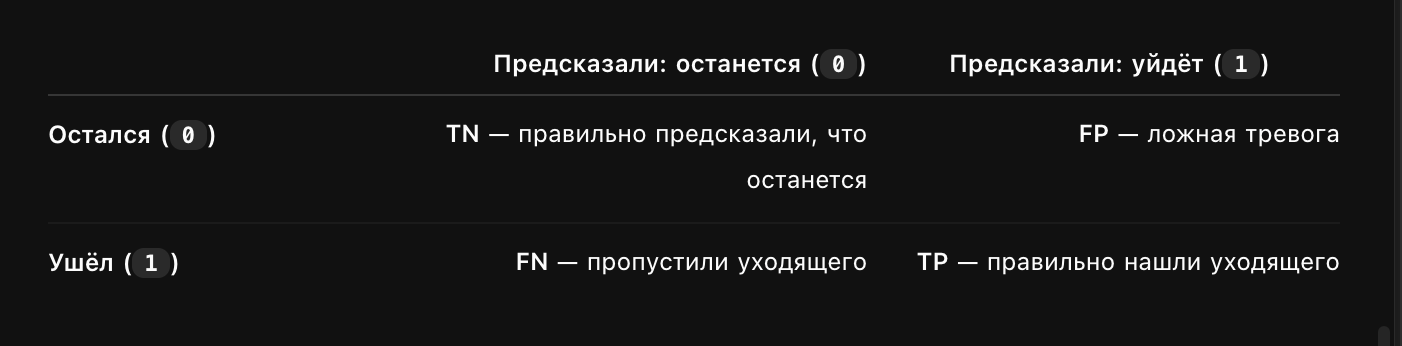

In [38]:
#эксперимент: исключение признака Contract Length

X_train_noLength = X_train.drop(columns=["Contract Length"])
X_val_noLength = X_val.drop(columns=["Contract Length"])

categorical_features_noLength = [
    "Gender",
    "Subscription Type"
]
numeric_features_noLength = [
    column
    for column in X_train_noLength.columns
    if column not in categorical_features_noLength
]

prepocessor_noLength = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features_noLength),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features_noLength),
    ]
)

model_noLength = Pipeline(
    steps=[
        ("prepocessor", prepocessor_noLength),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

model_noLength.fit(X_train_noLength, y_train)
y_pred_noLength = model_noLength.predict(X_val_noLength)
y_proba_noLength = model_noLength.predict_proba(X_val_noLength)[:, 1]

print(classification_report(y_val, y_pred_noLength))
print("confusion matrix")
print(confusion_matrix(y_val, y_pred_noLength))
print(f'roc-auc: {roc_auc_score(y_val, y_proba_noLength)}')

              precision    recall  f1-score   support

         0.0       0.82      0.85      0.83     38167
         1.0       0.88      0.85      0.87     50000

    accuracy                           0.85     88167
   macro avg       0.85      0.85      0.85     88167
weighted avg       0.85      0.85      0.85     88167

confusion matrix
[[32255  5912]
 [ 7252 42748]]
roc-auc: 0.9281073964419524


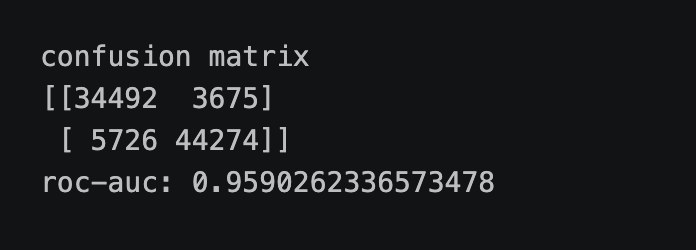

In [39]:
X_test = test_df.drop(columns=["Churn", "CustomerID"])
y_test = test_df["Churn"]
X_test_noLength = X_test.drop(columns=["Contract Length"])

y_pred_test = model.predict(X_test)
y_pred_test_noLength = model_noLength.predict(X_test_noLength)

y_proba_test = model.predict_proba(X_test)[:,1]
y_proba_test_noLength = model_noLength.predict_proba(X_test_noLength)[:,1]

print(classification_report(y_test, y_pred_test))
print("confusion matrix")
print(confusion_matrix(y_test, y_pred_test))
print(f'roc-auc: {roc_auc_score(y_test, y_proba_test)}')


              precision    recall  f1-score   support

           0       0.96      0.19      0.32     33881
           1       0.53      0.99      0.69     30493

    accuracy                           0.57     64374
   macro avg       0.74      0.59      0.50     64374
weighted avg       0.75      0.57      0.49     64374

confusion matrix
[[ 6564 27317]
 [  287 30206]]
roc-auc: 0.6894403096371685


In [40]:
print(classification_report(y_test, y_pred_test_noLength))
print("confusion_matrix")
print(confusion_matrix(y_test, y_pred_test_noLength))
print(f'roc-auc: {roc_auc_score(y_test, y_proba_test_noLength)}')

              precision    recall  f1-score   support

           0       0.94      0.23      0.37     33881
           1       0.53      0.98      0.69     30493

    accuracy                           0.59     64374
   macro avg       0.74      0.61      0.53     64374
weighted avg       0.75      0.59      0.52     64374

confusion_matrix
[[ 7813 26068]
 [  528 29965]]
roc-auc: 0.7749834038120228


удаление признака дало 1249 меньше ложных тревог, но на 241 больше пропущенных уходящих при пороге 0.5. 

contract length помогает на случайном validation, но ухудшает перенос на testing.

| Выборка | Вариант | ROC-AUC | Precision¹ | Recall¹ | F1¹ |
|---|---|---:|---:|---:|---:|
| Validation | С признаком | 0,959 | 0,923 | 0,885 | 0,904 |
| Validation | Без признака | 0,928 | 0,879 | 0,855 | 0,867 |
| Testing | С признаком | 0,689 | 0,525 | 0,991 | 0,686 |
| Testing | Без признака | 0,775 | 0,535 | 0,983 | 0,693 |

In [41]:
y_proba_train = model.predict_proba(X_train)[:,1]
y_proba_train_noLength = model_noLength.predict_proba(X_train_noLength)[:,1]

print(f"roc auc {roc_auc_score(y_train, y_proba_train)}")
print(f"roc auc noLength {roc_auc_score(y_train,y_proba_train_noLength)}")

roc auc 0.9597236192788853
roc auc noLength 0.9284811772597502


In [42]:
print("validation data")
print(f'roc-auc: {roc_auc_score(y_val, y_proba)}')
print(f'roc-auc: {roc_auc_score(y_val, y_proba_noLength)}')
print("test data")
print(f'roc-auc: {roc_auc_score(y_test, y_proba_test)}')
print(f'roc-auc: {roc_auc_score(y_test, y_proba_test_noLength)}')
print("train data")
print(f"roc auc {roc_auc_score(y_train, y_proba_train)}")
print(f"roc auc noLength {roc_auc_score(y_train,y_proba_train_noLength)}")

validation data
roc-auc: 0.9590262336573478
roc-auc: 0.9281073964419524
test data
roc-auc: 0.6894403096371685
roc-auc: 0.7749834038120228
train data
roc auc 0.9597236192788853
roc auc noLength 0.9284811772597502


In [43]:
support_train = train_df.groupby("Support Calls")["Churn"].agg(
    count="size",
    churn_rate="mean",
)

support_test = test_df.groupby("Support Calls")["Churn"].agg(
    count="size",
    churn_rate="mean",
)

support_comprasion = support_train.join(
    support_test, 
    lsuffix="_train",
    rsuffix="_test",
)

support_comprasion

,count_train,churn_rate_train,count_test,churn_rate_test
Support Calls,,,,
0.0,69875,0.302826,4967,0.242199
1.0,69476,0.303630,4929,0.228850
2.0,66571,0.315513,4812,0.231505
3.0,52729,0.416431,4723,0.248359
4.0,38750,0.584981,5148,0.318376
5.0,24918,0.947147,6657,0.604627
6.0,23554,1.000000,6639,0.606115
7.0,23870,1.000000,6599,0.617821
8.0,23559,1.000000,6649,0.609565


In [44]:
payment_train = train_df.groupby("Payment Delay")["Churn"].agg(
    count="size",
    churn_rate="mean",
)

payment_test = test_df.groupby("Payment Delay")["Churn"].agg(
    count="size",
    churn_rate="mean",
)

payment_comprasion = payment_train.join(
    payment_test, 
    lsuffix="_train",
    rsuffix="_test",
)

payment_comprasion

,count_train,churn_rate_train,count_test,churn_rate_test
Payment Delay,,,,
0.0,16904,0.466694,1594,0.095985
1.0,17021,0.457846,1539,0.095517
2.0,16822,0.466829,1531,0.116264
3.0,17025,0.465786,1543,0.107583
4.0,16938,0.463573,1588,0.098237
5.0,16744,0.466197,1568,0.098214
6.0,16954,0.466851,1541,0.088254
7.0,17027,0.463264,1539,0.107862
8.0,16892,0.471170,1559,0.098781


In [45]:
tenure_train = train_df.groupby("Tenure")["Churn"].agg(
    count="size",
    churn_rate="mean",
)

tenure_test = test_df.groupby("Tenure")["Churn"].agg(
    count="size",
    churn_rate="mean",
)

tenure_comprasion = tenure_train.join(
    tenure_test, 
    lsuffix="_train",
    rsuffix="_test",
)

tenure_comprasion

,count_train,churn_rate_train,count_test,churn_rate_test
Tenure,,,,
1.0,6407,0.653660,933,0.362272
2.0,6575,0.647148,937,0.353255
3.0,6417,0.634409,976,0.334016
4.0,6606,0.641387,958,0.346555
5.0,6669,0.645074,967,0.343330
6.0,7704,0.535306,939,0.304579
7.0,7569,0.545779,1001,0.317682
8.0,7670,0.553325,912,0.298246
9.0,7534,0.537961,912,0.271930


Между файлами различаются зависимости признаков от целевой переменной. В training обнаружены жёсткие пороговые закономерности, которые не сохраняются в testing. Причина формирования этих зависимостей неизвестна.

In [46]:
def feature_comprassion(feature, train_df, test_df, target="Churn"):

    def summarize(df):
        return df.groupby(feature)[target].agg(
            count="size",
            churn_rate="mean"
        )

    feature_train = summarize(train_df)
    feature_test = summarize(test_df)
    
    comprassion = feature_train.join(
        feature_test,
        how="outer",
        lsuffix="_train",
        rsuffix="_test"
    )
    return comprassion

feature_comprassion("Support Calls", train_df, test_df)

,count_train,churn_rate_train,count_test,churn_rate_test
Support Calls,,,,
0.0,69875,0.302826,4967,0.242199
1.0,69476,0.303630,4929,0.228850
2.0,66571,0.315513,4812,0.231505
3.0,52729,0.416431,4723,0.248359
4.0,38750,0.584981,5148,0.318376
5.0,24918,0.947147,6657,0.604627
6.0,23554,1.000000,6639,0.606115
7.0,23870,1.000000,6599,0.617821
8.0,23559,1.000000,6649,0.609565


In [47]:
features = [col for col in train_df.columns if col not in ("CustomerID", "Churn", "Total Spend")]

for feature in features:
    display(feature_comprassion(feature, train_df, test_df))

,count_train,churn_rate_train,count_test,churn_rate_test
Age,,,,
18.0,8219,0.647646,1274,0.448980
19.0,8073,0.644494,1279,0.444097
20.0,9553,0.536271,1388,0.443804
21.0,9574,0.542198,1251,0.418865
22.0,9639,0.543521,1266,0.449447
23.0,9513,0.537370,1285,0.491051
24.0,9465,0.548759,1252,0.451278
25.0,9647,0.538095,1348,0.445846
26.0,9692,0.535080,1281,0.439500


,count_train,churn_rate_train,count_test,churn_rate_test
Gender,,,,
Female,190580,0.666691,34353,0.550490
Male,250252,0.491269,30021,0.385797


,count_train,churn_rate_train,count_test,churn_rate_test
Tenure,,,,
1.0,6407,0.653660,933,0.362272
2.0,6575,0.647148,937,0.353255
3.0,6417,0.634409,976,0.334016
4.0,6606,0.641387,958,0.346555
5.0,6669,0.645074,967,0.343330
6.0,7704,0.535306,939,0.304579
7.0,7569,0.545779,1001,0.317682
8.0,7670,0.553325,912,0.298246
9.0,7534,0.537961,912,0.271930


,count_train,churn_rate_train,count_test,churn_rate_test
Usage Frequency,,,,
1.0,13797,0.617163,2615,0.694455
2.0,13633,0.621800,2633,0.691986
3.0,13843,0.607672,2488,0.610932
4.0,13549,0.614510,2427,0.611454
5.0,13716,0.613955,2337,0.607189
6.0,13746,0.619598,2072,0.454151
7.0,13555,0.598377,2066,0.434656
8.0,13725,0.617632,2016,0.406746
9.0,13770,0.612273,2064,0.434109


,count_train,churn_rate_train,count_test,churn_rate_test
Support Calls,,,,
0.0,69875,0.302826,4967,0.242199
1.0,69476,0.303630,4929,0.228850
2.0,66571,0.315513,4812,0.231505
3.0,52729,0.416431,4723,0.248359
4.0,38750,0.584981,5148,0.318376
5.0,24918,0.947147,6657,0.604627
6.0,23554,1.000000,6639,0.606115
7.0,23870,1.000000,6599,0.617821
8.0,23559,1.000000,6649,0.609565


,count_train,churn_rate_train,count_test,churn_rate_test
Payment Delay,,,,
0.0,16904,0.466694,1594,0.095985
1.0,17021,0.457846,1539,0.095517
2.0,16822,0.466829,1531,0.116264
3.0,17025,0.465786,1543,0.107583
4.0,16938,0.463573,1588,0.098237
5.0,16744,0.466197,1568,0.098214
6.0,16954,0.466851,1541,0.088254
7.0,17027,0.463264,1539,0.107862
8.0,16892,0.471170,1559,0.098781


,count_train,churn_rate_train,count_test,churn_rate_test
Subscription Type,,,,
Basic,143026,0.581782,21451,0.482775
Premium,148678,0.559417,21421,0.464964
Standard,149128,0.560700,21502,0.473305


,count_train,churn_rate_train,count_test,churn_rate_test
Contract Length,,,,
Annual,177198,0.460761,21410,0.462167
Monthly,87104,1.000000,22130,0.516087
Quarterly,176530,0.460256,20834,0.440482


,count_train,churn_rate_train,count_test,churn_rate_test
Last Interaction,,,,
1.0,16727,0.488133,2116,0.479206
2.0,16663,0.494569,2118,0.466478
3.0,16711,0.495482,2162,0.488437
4.0,16570,0.490465,2058,0.468902
5.0,16710,0.491382,2087,0.485386
6.0,16746,0.491998,2158,0.477294
7.0,16914,0.493969,2291,0.483195
8.0,16762,0.489858,2210,0.472398
9.0,16532,0.494798,2088,0.492816


данные слишком синтетические, validation AUC = 0.96, testing = 0.69-0.77. 

причина — разные детерминированные правила в файлах. Многие проекты на этом датасете хвастаются как раз этим AUC 0.96.

при payment delay > 20 churn_rate_train взлетает до значения 1 и не меняется, подобные дефекты наблюдаются во многих признаках.

также исходя из логики датасета все кто остались в подписке ни разу не платили помесячно, что не является реалистичным подходом. 